In [1]:
# 1. IMPORTAÇÃO DE BIBLIOTECAS E FERRAMENTAS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

In [2]:
# 2. CARREGAMENTO E LIMPEZA DOS DADOS
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Removendo o ID do cliente (não será necessário para prever comportamento)
df.drop('customerID', axis=1, inplace=True)

# Corrigindo espaços em branco na coluna de Total Gasto e converter para número
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

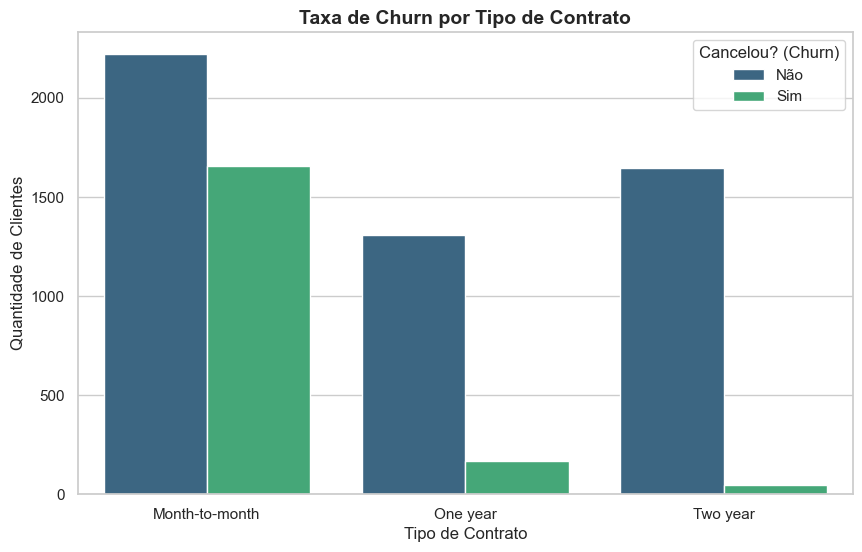

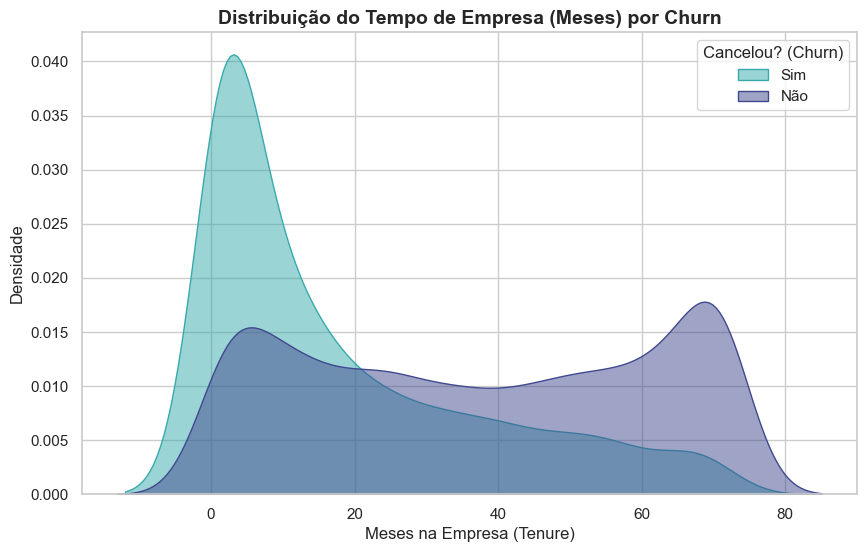

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


In [3]:
# 3. ANÁLISE EXPLORATÓRIA E GERAÇÃO DE GRÁFICOS
# Configurando o estilo dos gráficos
sns.set_theme(style="whitegrid")

# 1. Gráfico de Churn por Tipo de Contrato
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Contract', hue='Churn', palette='viridis')
plt.title('Taxa de Churn por Tipo de Contrato', fontsize=14, fontweight='bold')
plt.xlabel('Tipo de Contrato', fontsize=12)
plt.ylabel('Quantidade de Clientes', fontsize=12)
plt.legend(title='Cancelou? (Churn)', labels=['Não', 'Sim'])
plt.savefig('churn_por_contrato.png', bbox_inches='tight', dpi=300)
plt.show()

# 2. Gráfico de Distribuição do Tempo de Empresa (Tenure)
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, x='tenure', hue='Churn', fill=True, common_norm=False, palette='mako', alpha=0.5)
plt.title('Distribuição do Tempo de Empresa (Meses) por Churn', fontsize=14, fontweight='bold')
plt.xlabel('Meses na Empresa (Tenure)', fontsize=12)
plt.ylabel('Densidade', fontsize=12)
plt.legend(title='Cancelou? (Churn)', labels=['Sim', 'Não'])
plt.savefig('churn_por_tempo.png', bbox_inches='tight', dpi=300)
plt.show()

# Verificando a distribuição da classe alvo
print(df['Churn'].value_counts(normalize=True))

In [4]:
# 4. TRANSFORMAÇÃO DE TEXTO EM NÚMEROS (ENCODING)
colunas_textos = df.select_dtypes(include=['object']).columns

le = LabelEncoder()
for col in colunas_textos:
    df[col] = le.fit_transform(df[col])

C:\Users\Magna Oliveira\AppData\Local\Temp\ipykernel_11240\3148468553.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colunas_textos = df.select_dtypes(include=['object']).columns


In [5]:
# 5. SEPARAÇÃO EM TREINO E TESTE
x = df.drop('Churn', axis=1)
y = df['Churn']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [6]:
# 6. TRATAMENTO DE VALORES NULOS COM A MEDIANA
mediana_total = x_train['TotalCharges'].median()
x_train['TotalCharges'] = x_train['TotalCharges'].fillna(mediana_total)
x_test['TotalCharges'] = x_test['TotalCharges'].fillna(mediana_total)

print("Quantidade de nulos atualizada em x_train:", x_train['TotalCharges'].isnull().sum())

Quantidade de nulos atualizada em x_train: 0


In [7]:
# 7. MODELO 1: RANDOM FOREST CLASSIFIER (PESOS BALANCEADOS)
modelo_balanceado = RandomForestClassifier(class_weight='balanced', random_state=42)
modelo_balanceado.fit(x_train, y_train)
novas_previsoes = modelo_balanceado.predict(x_test)

print("--- RESULTADO: RANDOM FOREST ---")
print(classification_report(y_test, novas_previsoes))

--- RESULTADO: RANDOM FOREST ---
              precision    recall  f1-score   support

           0       0.83      0.92      0.87      1036
           1       0.68      0.46      0.55       373

    accuracy                           0.80      1409
   macro avg       0.75      0.69      0.71      1409
weighted avg       0.79      0.80      0.79      1409



In [8]:
# 8. MODELO 2: RANDOM FOREST + TÉCNICA SMOTE
smote = SMOTE(random_state=42)
x_train_res, y_train_res = smote.fit_resample(x_train, y_train)

modelo_smote = RandomForestClassifier(random_state=42)
modelo_smote.fit(x_train_res, y_train_res)
previsoes_smote = modelo_smote.predict(x_test)

print("--- RESULTADO: RANDOM FOREST + SMOTE ---")
print(classification_report(y_test, previsoes_smote))

--- RESULTADO: RANDOM FOREST + SMOTE ---
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      1036
           1       0.58      0.58      0.58       373

    accuracy                           0.78      1409
   macro avg       0.71      0.71      0.71      1409
weighted avg       0.78      0.78      0.78      1409



In [9]:
# 9. MODELO 3: XGBOOST BALANCEADO
classes = y_train.value_counts()
proporcao = classes[0] / classes[1]

modelo_xgb = XGBClassifier(scale_pos_weight=proporcao, random_state=42, eval_metric='logloss')
modelo_xgb.fit(x_train, y_train)
previsoes_xgb = modelo_xgb.predict(x_test)

print("--- RESULTADO: XGBOOST BALANCEADO ---")
print(classification_report(y_test, previsoes_xgb))

--- RESULTADO: XGBOOST BALANCEADO ---
              precision    recall  f1-score   support

           0       0.87      0.80      0.83      1036
           1       0.54      0.67      0.60       373

    accuracy                           0.76      1409
   macro avg       0.71      0.73      0.71      1409
weighted avg       0.78      0.76      0.77      1409



In [10]:
# 10. MODELO VENCEDOR: XGBOOST + AJUSTE DE LIMIAR (THRESHOLD TUNING)
probabilidades = modelo_xgb.predict_proba(x_test)[:, 1]
novo_limiar = 0.35
previsoes_ajustadas = (probabilidades >= novo_limiar).astype(int)

print("--- RESULTADO FINAL: XGBOOST + AJUSTE DE LIMIAR (0.35) ---")
print(classification_report(y_test, previsoes_ajustadas))

--- RESULTADO FINAL: XGBOOST + AJUSTE DE LIMIAR (0.35) ---
              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1036
           1       0.51      0.78      0.62       373

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.76      1409

